# 🤖 LLM Text Classifier — Sentence Embeddings

In [ ]:
# # CELL 1 — INSTALL  (run once, safe to skip on subsequent runs)
# import subprocess, sys
# pkgs = [
#     'sentence-transformers', 'lightgbm', 'xgboost', 'catboost',
#     'textstat', 'nltk', 'pyarrow', 'openpyxl', 'scikit-learn',
#     'transformers', 'accelerate',
# ]
# for p in pkgs:
#     subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', p],
#                    capture_output=True)
# import nltk
# for d in ['punkt', 'punkt_tab', 'stopwords']:
#     nltk.download(d, quiet=True)
# print('All packages ready')


All packages ready


In [1]:
# CELL 2 — IMPORTS & MEMORY CLEARING
import os
import gc
import json
import time
import torch
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from joblib import dump, load

# Sklearn Classifiers
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.neural_network import MLPClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# PyTorch sequence models
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings('ignore')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"✅ Using Device: {DEVICE}")

✅ Using Device: cuda


In [2]:
# CELL 3 — CONFIGURATION
# Set your paths here. Ensure these point to the exact locations of your data.
DATA_DIR = Path(r"C:\Users\arjun\Downloads\llm_sbert_complete\data") # <--- UPDATE THIS
TRAIN_PATH = DATA_DIR / "normal_train.parquet"
VAL_PATH = DATA_DIR / "val.parquet" 
TEST_PATH = DATA_DIR / "test.parquet"

# Create Output Directories
OUTPUT_DIR = Path("./Project_Output")
CACHE = OUTPUT_DIR / "Cache"
MODELS_DIR = OUTPUT_DIR / "Saved_Models"
RESULTS_DIR = OUTPUT_DIR / "Results"

for p in [CACHE, MODELS_DIR, RESULTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# Define models to test
EMBEDDING_MODELS = {
    "MiniLM": "all-MiniLM-L6-v2",
    "MPNet": "all-mpnet-base-v2",
    "BGE": "BAAI/bge-base-en-v1.5",
    "E5": "intfloat/e5-base-v2"
}

print(f"✅ Directories ready. Output mapped to: {OUTPUT_DIR.absolute()}")

✅ Directories ready. Output mapped to: c:\Users\arjun\Downloads\llm_sbert_complete\Project_Output


In [3]:
# CELL 4 — EXTRACT RAW TEXT AND SAVE TO DISK
# This handles the column renaming safely and extracts text arrays.

def safe_load_data(path, name):
    df = pd.read_parquet(path)
    # FIX: Robust Column Renaming based on what actually exists
    cols = df.columns.tolist()
    
    # 1. Find Text Column
    text_col = None
    for tc in ['text', 'generation', 'source_text', 'content']:
        if tc in cols: text_col = tc; break
            
    # 2. Find Label Column
    label_col = None
    for lc in ['label', 'generated_by', 'model', 'target', 'class']:
        if lc in cols: label_col = lc; break
            
    if not text_col or not label_col:
        raise KeyError(f"[{name}] Could not find text/label columns. Available cols: {cols}")
        
    df = df.rename(columns={text_col: 'text_input', label_col: 'target_label'})
    
    # Clean data: drop NaNs and very short texts
    df = df.dropna(subset=['text_input', 'target_label']).reset_index(drop=True)
    df['text_input'] = df['text_input'].astype(str)
    df = df[df['text_input'].str.len() >= 20].reset_index(drop=True)
    
    print(f"  {name} Data -> Rows: {len(df):,} | Labels: {df['target_label'].nunique()}")
    return df['text_input'].values, df['target_label'].values

if not (CACHE / 'y_tr.npy').exists():
    print("Loading Parquet files...")
    X_text_tr, y_tr_raw = safe_load_data(TRAIN_PATH, "Train")
    X_text_vl, y_vl_raw = safe_load_data(VAL_PATH, "Val")
    X_text_ts, y_ts_raw = safe_load_data(TEST_PATH, "Test")
    
    print("Encoding Labels...")
    LE = LabelEncoder()
    y_tr = LE.fit_transform(y_tr_raw)
    y_vl = LE.transform(y_vl_raw)
    y_ts = LE.transform(y_ts_raw)
    
    # Save target mapping and arrays
    dump(LE, CACHE / 'label_encoder.joblib')
    np.save(CACHE / 'y_tr.npy', y_tr)
    np.save(CACHE / 'y_vl.npy', y_vl)
    np.save(CACHE / 'y_ts.npy', y_ts)
    np.save(CACHE / 'X_text_tr.npy', X_text_tr)
    np.save(CACHE / 'X_text_vl.npy', X_text_vl)
    np.save(CACHE / 'X_text_ts.npy', X_text_ts)
    
    del X_text_tr, y_tr_raw, X_text_vl, y_vl_raw, X_text_ts, y_ts_raw
    gc.collect()
    print("✅ Raw texts and labels cached.")
else:
    print("✅ Cache detected. Data already parsed. Proceed to embeddings.")

✅ Cache detected. Data already parsed. Proceed to embeddings.


In [4]:
# CELL 5 — EVALUATION & SAVING ENGINE
# Independent evaluation wrapper to standardize output tracking.

def evaluate_and_save(model, model_name, embed_name, X_tr, y_tr, X_vl, y_vl, X_ts, y_ts):
    t0 = time.time()
    
    # Track Train Acc (helps identify overfitting)
    train_preds = model.predict(X_tr)
    train_acc = accuracy_score(y_tr, train_preds)
    
    # Val Metrics
    val_preds = model.predict(X_vl)
    val_acc = accuracy_score(y_vl, val_preds)
    
    # Test Metrics
    ts_preds = model.predict(X_ts)
    ts_acc = accuracy_score(y_ts, ts_preds)
    ts_prec = precision_score(y_ts, ts_preds, average='weighted', zero_division=0)
    ts_rec = recall_score(y_ts, ts_preds, average='weighted', zero_division=0)
    ts_f1 = f1_score(y_ts, ts_preds, average='weighted', zero_division=0)
    
    try:
        ts_probs = model.predict_proba(X_ts)
        # Handle binary vs multiclass ROC-AUC
        if len(np.unique(y_ts)) == 2:
            ts_roc = roc_auc_score(y_ts, ts_probs[:, 1])
        else:
            ts_roc = roc_auc_score(y_ts, ts_probs, multi_class='ovr')
    except:
        ts_roc = 0.0 # Some models (like LinearSVC) don't have predict_proba by default
        
    t1 = time.time() - t0
    
    # Compile Results
    res = {
        "Embedding": embed_name,
        "Classifier": model_name,
        "Train_Acc": round(train_acc, 4),
        "Val_Acc": round(val_acc, 4),
        "Test_Acc": round(ts_acc, 4),
        "Precision": round(ts_prec, 4),
        "Recall": round(ts_rec, 4),
        "F1_Score": round(ts_f1, 4),
        "ROC_AUC": round(ts_roc, 4),
        "Time_Sec": round(t1, 1)
    }
    
    # Save Model to Disk
    model_path = MODELS_DIR / f"{embed_name}_{model_name}.joblib"
    dump(model, model_path)
    
    # Append to Master CSV
    csv_path = RESULTS_DIR / "master_results.csv"
    res_df = pd.DataFrame([res])
    if csv_path.exists():
        res_df.to_csv(csv_path, mode='a', header=False, index=False)
    else:
        res_df.to_csv(csv_path, index=False)
        
    print(f"🟢 [{embed_name} + {model_name}] Saved! Test Acc: {ts_acc:.4f} | F1: {ts_f1:.4f}")
    return res

In [20]:
# CELL 6 — EXTRACT EMBEDDINGS (INDEPENDENT)
# This will extract embeddings, save as numpy files, and clear memory.

from sentence_transformers import SentenceTransformer

def process_embeddings(embed_key, hf_path):
    train_out = CACHE / f'X_tr_{embed_key}.npy'
    if train_out.exists():
        print(f"⏩ {embed_key} embeddings already exist. Skipping.")
        return

    print(f"\n--- Extracting {embed_key} Embeddings ---")
    model = SentenceTransformer(hf_path, device=DEVICE)
    
    # ==========================================
    # 1. PROCESS TRAIN DATA
    # ==========================================
    # Added .tolist() because SentenceTransformers requires a native Python list
    X_text_tr = np.load(CACHE / 'X_text_tr.npy', allow_pickle=True).tolist()
    
    # normalize_embeddings=True helps classifiers like LinearSVC converge faster
    X_tr = model.encode(X_text_tr, batch_size=256, show_progress_bar=True, normalize_embeddings=True).astype(np.float32)
    np.save(train_out, X_tr)
    
    # Delete from RAM immediately before loading the next split
    del X_tr, X_text_tr
    gc.collect()
    
    # ==========================================
    # 2. PROCESS VALIDATION DATA
    # ==========================================
    X_text_vl = np.load(CACHE / 'X_text_vl.npy', allow_pickle=True).tolist()
    X_vl = model.encode(X_text_vl, batch_size=256, show_progress_bar=True, normalize_embeddings=True).astype(np.float32)
    np.save(CACHE / f'X_vl_{embed_key}.npy', X_vl)
    
    del X_vl, X_text_vl
    gc.collect()
    
    # ==========================================
    # 3. PROCESS TEST DATA
    # ==========================================
    X_text_ts = np.load(CACHE / 'X_text_ts.npy', allow_pickle=True).tolist()
    X_ts = model.encode(X_text_ts, batch_size=256, show_progress_bar=True, normalize_embeddings=True).astype(np.float32)
    np.save(CACHE / f'X_ts_{embed_key}.npy', X_ts)
    
    del X_ts, X_text_ts
    gc.collect()
    
    # ==========================================
    # 4. CLEANUP GPU VRAM
    # ==========================================
    del model
    torch.cuda.empty_cache()
    gc.collect()
    print(f"✅ {embed_key} embeddings saved successfully.")

# Run the extraction for all defined models
for key, path in EMBEDDING_MODELS.items():
    process_embeddings(key, path)


--- Extracting MiniLM Embeddings ---


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1407 [00:00<?, ?it/s]

Batches:   0%|          | 0/389 [00:00<?, ?it/s]

...

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/1407 [00:00<?, ?it/s]

Batches:   0%|          | 0/389 [00:00<?, ?it/s]

Batches:   0%|          | 0/389 [00:00<?, ?it/s]

✅ E5 embeddings saved successfully.


In [6]:
# CELL 7 — TRAIN STANDARD CLASSIFIERS
# Independent Cell. Memory optimized using mmap_mode.

def get_ml_classifiers():
    return {
        "LogisticRegression": LogisticRegression(max_iter=500, n_jobs=-1),
        "LinearSVC": LinearSVC(max_iter=1000, dual=False),
        "RandomForest": RandomForestClassifier(n_estimators=100, n_jobs=-1),
        # "ExtraTrees": ExtraTreesClassifier(n_estimators=100, n_jobs=-1),
        # # "LightGBM": LGBMClassifier(n_estimators=200, n_jobs=-1, verbose=-1),
        # "XGBoost": XGBClassifier(n_estimators=200, n_jobs=-1, eval_metric='logloss'),
        # "CatBoost": CatBoostClassifier(iterations=200, task_type="GPU" if DEVICE=='cuda' else "CPU", verbose=0),
        "MLP": MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=300),
        "ComplementNB": ComplementNB() 
    }

y_tr = np.load(CACHE / 'y_tr.npy')
y_vl = np.load(CACHE / 'y_vl.npy')
y_ts = np.load(CACHE / 'y_ts.npy')

# Iterate through each embedding type
for embed_name in EMBEDDING_MODELS.keys():
    print(f"\n======== Training on {embed_name} ========")
    
    # Load embeddings using memory mapping (uses ZERO actual RAM until computation)
    X_tr = np.load(CACHE / f'X_tr_{embed_name}.npy', mmap_mode='r')
    X_vl = np.load(CACHE / f'X_vl_{embed_name}.npy', mmap_mode='r')
    X_ts = np.load(CACHE / f'X_ts_{embed_name}.npy', mmap_mode='r')
    
    models = get_ml_classifiers()
    
    for clf_name, clf in models.items():
        # ComplementNB needs strictly positive features, embed features can be negative
        if clf_name == "ComplementNB":
            scaler = MinMaxScaler()
            X_tr_scaled = scaler.fit_transform(X_tr)
            X_vl_scaled = scaler.transform(X_vl)
            X_ts_scaled = scaler.transform(X_ts)
            clf.fit(X_tr_scaled, y_tr)
            evaluate_and_save(clf, clf_name, embed_name, X_tr_scaled, y_tr, X_vl_scaled, y_vl, X_ts_scaled, y_ts)
            del X_tr_scaled, X_vl_scaled, X_ts_scaled
        else:
            clf.fit(X_tr, y_tr)
            evaluate_and_save(clf, clf_name, embed_name, X_tr, y_tr, X_vl, y_vl, X_ts, y_ts)
            
        gc.collect() # Clean up RAM after every model!


======== Training on MiniLM ========
🟢 [MiniLM + LogisticRegression] Saved! Test Acc: 0.3168 | F1: 0.3065
🟢 [MiniLM + LinearSVC] Saved! Test Acc: 0.3059 | F1: 0.2761
🟢 [MiniLM + RandomForest] Saved! Test Acc: 0.5535 | F1: 0.5512
🟢 [MiniLM + MLP] Saved! Test Acc: 0.4672 | F1: 0.4623
🟢 [MiniLM + ComplementNB] Saved! Test Acc: 0.1931 | F1: 0.1641

======== Training on MPNet ========
🟢 [MPNet + LogisticRegression] Saved! Test Acc: 0.3541 | F1: 0.3461
🟢 [MPNet + LinearSVC] Saved! Test Acc: 0.3575 | F1: 0.3365
🟢 [MPNet + RandomForest] Saved! Test Acc: 0.5642 | F1: 0.5620
🟢 [MPNet + MLP] Saved! Test Acc: 0.5213 | F1: 0.5166
🟢 [MPNet + ComplementNB] Saved! Test Acc: 0.1577 | F1: 0.1305

======== Training on BGE ========
🟢 [BGE + LogisticRegression] Saved! Test Acc: 0.4101 | F1: 0.4031
🟢 [BGE + LinearSVC] Saved! Test Acc: 0.4145 | F1: 0.3967
🟢 [BGE + RandomForest] Saved! Test Acc: 0.5698 | F1: 0.5685
🟢 [BGE + MLP] Saved! Test Acc: 0.5843 | F1: 0.5814
🟢 [BGE + ComplementNB] Saved! Test Acc: 0.1

In [8]:
# ================== CELL 8 — TRAIN SEQUENCE MODELS (FIXED) ==================

class SeqModel(nn.Module):
    def __init__(self, embed_dim, num_classes, model_type='LSTM'):
        super().__init__()
        self.model_type = model_type

        if model_type == 'LSTM':
            self.rnn = nn.LSTM(embed_dim, 128, batch_first=True)

        elif model_type == 'BiLSTM':
            self.rnn = nn.LSTM(embed_dim, 128, batch_first=True, bidirectional=True)

        elif model_type == 'GRU':
            self.rnn = nn.GRU(embed_dim, 128, batch_first=True)

        elif model_type == 'RNN':
            self.rnn = nn.RNN(embed_dim, 128, batch_first=True)

        elif model_type == 'TextCNN':
            # FIXED CNN
            self.conv1 = nn.Conv1d(in_channels=embed_dim, out_channels=128, kernel_size=1)

        self.seq_out_dim = 256 if model_type == 'BiLSTM' else 128
        self.fc = nn.Linear(self.seq_out_dim, num_classes)

    def forward(self, x):
        # x: [batch, 1, embed_dim]

        if self.model_type == 'TextCNN':
            # FIX: reshape for CNN
            x = x.squeeze(1)                 # [batch, embed_dim]
            x = x.unsqueeze(2)               # [batch, embed_dim, 1]
            x = self.conv1(x)                # [batch, 128, 1]
            x = x.squeeze(2)                 # [batch, 128]

        else:
            out, _ = self.rnn(x)             # [batch, 1, hidden]
            x = out[:, -1, :]                # [batch, hidden]

        return self.fc(x)


# ================== WRAPPER ==================

class PyTorchSklearnWrapper:
    def __init__(self, model_type, embed_dim, num_classes, epochs=5, batch_size=256):
        self.model_type = model_type
        self.epochs = epochs
        self.batch_size = batch_size
        self.device = DEVICE

        self.model = SeqModel(embed_dim, num_classes, model_type).to(self.device)

        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=1e-3)

    def _create_loader(self, X, y=None, shuffle=False):
        X_tensor = torch.tensor(X, dtype=torch.float32).unsqueeze(1)

        if y is not None:
            y_tensor = torch.tensor(y, dtype=torch.long)
            dataset = TensorDataset(X_tensor, y_tensor)
        else:
            dataset = TensorDataset(X_tensor)

        return DataLoader(dataset, batch_size=self.batch_size, shuffle=shuffle)

    def fit(self, X, y):
        loader = self._create_loader(X, y, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            for bx, by in loader:
                bx, by = bx.to(self.device), by.to(self.device)

                self.optimizer.zero_grad()
                out = self.model(bx)
                loss = self.criterion(out, by)

                loss.backward()
                self.optimizer.step()

    def predict(self, X):
        loader = self._create_loader(X)

        self.model.eval()
        preds = []

        with torch.no_grad():
            for (bx,) in loader:
                out = self.model(bx.to(self.device))
                preds.extend(torch.argmax(out, dim=1).cpu().numpy())

        return np.array(preds)

    def predict_proba(self, X):
        loader = self._create_loader(X)

        self.model.eval()
        probs = []

        with torch.no_grad():
            for (bx,) in loader:
                out = torch.softmax(self.model(bx.to(self.device)), dim=1)
                probs.extend(out.cpu().numpy())

        return np.array(probs)


# ================== TRAIN LOOP ==================

y_tr = np.load(CACHE / 'y_tr.npy')
y_vl = np.load(CACHE / 'y_vl.npy')
y_ts = np.load(CACHE / 'y_ts.npy')

num_classes = len(np.unique(y_tr))

seq_architectures = ['RNN', 'LSTM', 'BiLSTM', 'GRU', 'TextCNN']

for embed_name in EMBEDDING_MODELS.keys():
    print(f"\n======== Training DL Models on {embed_name} ========")

    X_tr = np.load(CACHE / f'X_tr_{embed_name}.npy')
    X_vl = np.load(CACHE / f'X_vl_{embed_name}.npy')
    X_ts = np.load(CACHE / f'X_ts_{embed_name}.npy')

    embed_dim = X_tr.shape[1]

    for arch in seq_architectures:
        print(f"\n--- {arch} ---")

        model = PyTorchSklearnWrapper(arch, embed_dim, num_classes)

        model.fit(X_tr, y_tr)

        evaluate_and_save(
            model, arch, embed_name,
            X_tr, y_tr,
            X_vl, y_vl,
            X_ts, y_ts
        )

        # CLEAN GPU MEMORY
        del model
        torch.cuda.empty_cache()
        gc.collect()

    del X_tr, X_vl, X_ts
    gc.collect()


======== Training DL Models on MiniLM ========

--- RNN ---
🟢 [MiniLM + RNN] Saved! Test Acc: 0.3128 | F1: 0.3057

--- LSTM ---
🟢 [MiniLM + LSTM] Saved! Test Acc: 0.3941 | F1: 0.3828

--- BiLSTM ---
🟢 [MiniLM + BiLSTM] Saved! Test Acc: 0.4103 | F1: 0.4029

--- GRU ---
🟢 [MiniLM + GRU] Saved! Test Acc: 0.3897 | F1: 0.3808

--- TextCNN ---
🟢 [MiniLM + TextCNN] Saved! Test Acc: 0.3107 | F1: 0.2977

======== Training DL Models on MPNet ========

--- RNN ---
🟢 [MPNet + RNN] Saved! Test Acc: 0.3509 | F1: 0.3431

--- LSTM ---
🟢 [MPNet + LSTM] Saved! Test Acc: 0.4174 | F1: 0.4083

--- BiLSTM ---
🟢 [MPNet + BiLSTM] Saved! Test Acc: 0.4393 | F1: 0.4311

--- GRU ---
🟢 [MPNet + GRU] Saved! Test Acc: 0.4123 | F1: 0.4046

--- TextCNN ---
🟢 [MPNet + TextCNN] Saved! Test Acc: 0.3519 | F1: 0.3438

======== Training DL Models on BGE ========

--- RNN ---
🟢 [BGE + RNN] Saved! Test Acc: 0.4014 | F1: 0.3937

--- LSTM ---
🟢 [BGE + LSTM] Saved! Test Acc: 0.4678 | F1: 0.4609

--- BiLSTM ---
🟢 [BGE + BiLSTM] 


🚀 GLOBAL RESULTS RANKED BY TEST ACCURACY


,Embedding,Classifier,Train_Acc,Val_Acc,Test_Acc,Precision,Recall,F1_Score,ROC_AUC,Time_Sec
0,E5,MLP,0.6859,0.6301,0.6301,0.6298,0.6301,0.6271,0.9464,2.3
1,BGE,MLP,0.6834,0.5843,0.5843,0.5816,0.5843,0.5814,0.9296,2.5
2,E5,RandomForest,1.0000,0.5772,0.5772,0.5770,0.5772,0.5754,0.8978,10.5
3,BGE,RandomForest,1.0000,0.5698,0.5698,0.5699,0.5698,0.5685,0.8912,11.5
4,MPNet,RandomForest,1.0000,0.5642,0.5642,0.5629,0.5642,0.5620,0.8862,11.3
5,MiniLM,RandomForest,0.9999,0.5535,0.5535,0.5545,0.5535,0.5512,0.8808,9.2
6,MPNet,MLP,0.6314,0.5213,0.5213,0.5159,0.5213,0.5166,0.9077,2.6
7,E5,BiLSTM,0.5018,0.4940,0.4940,0.4954,0.4940,0.4849,0.8995,14.5
8,BGE,BiLSTM,0.5071,0.4925,0.4925,0.4953,0.4925,0.4876,0.8989,13.7
9,E5,LinearSVC,0.4895,0.4838,0.4838,0.4783,0.4838,0.4696,0.0000,2.8


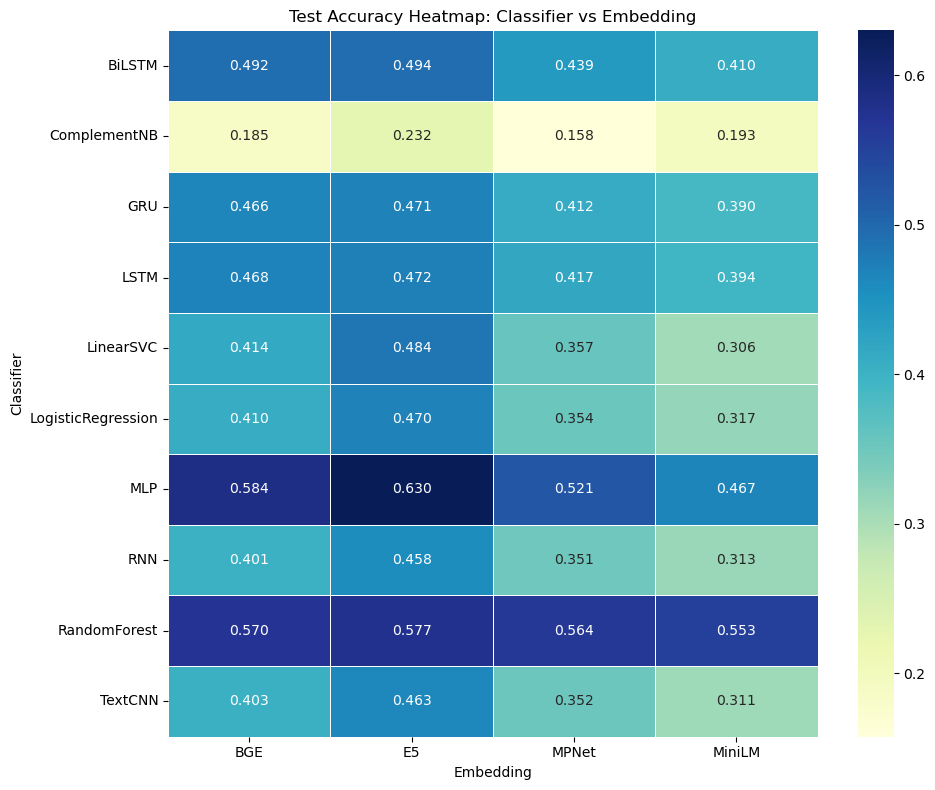

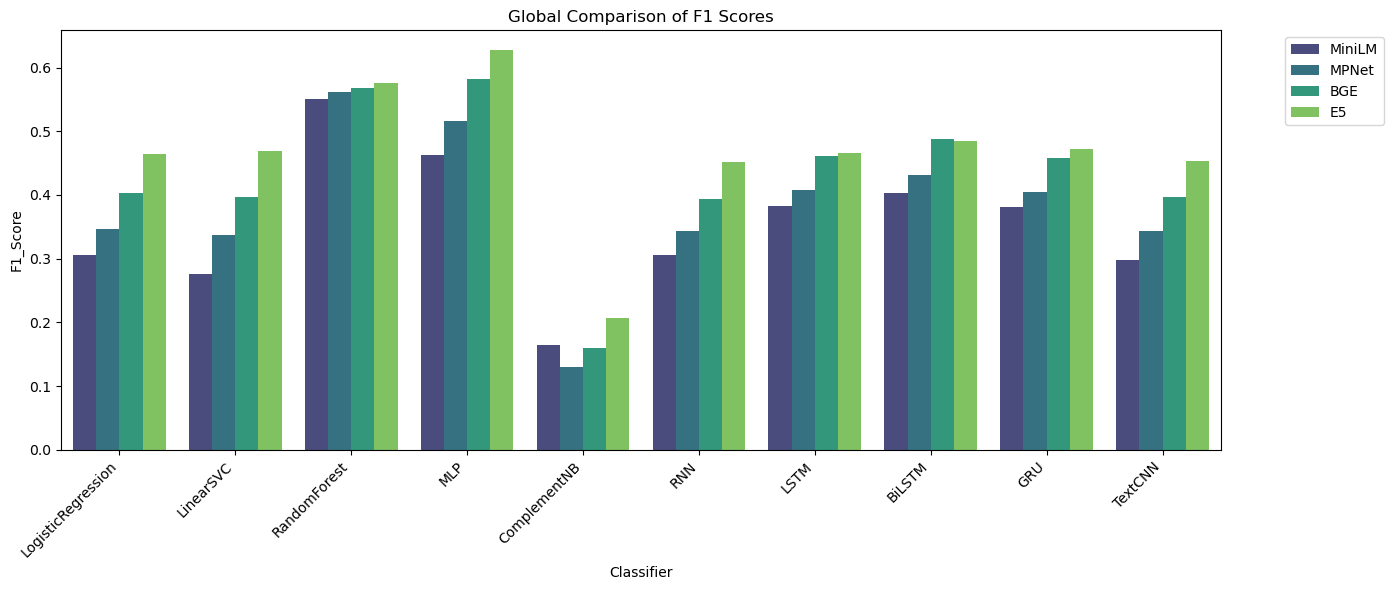

✅ All Tables and Charts saved to c:\Users\arjun\Downloads\llm_sbert_complete\Project_Output\Results


In [9]:
# CELL 9 — GLOBAL RESULTS COMPILATION
# Independent Cell. Reads the appended CSV and generates massive visual comparisons.

csv_path = RESULTS_DIR / "master_results.csv"
if not csv_path.exists():
    print("No results found. Run previous cells first.")
else:
    df_results = pd.read_csv(csv_path)
    
    # Drop duplicates in case a cell was run twice accidentally
    df_results = df_results.drop_duplicates(subset=['Embedding', 'Classifier'], keep='last')
    
    print("\n" + "="*80)
    print("🚀 GLOBAL RESULTS RANKED BY TEST ACCURACY")
    print("="*80)
    display_df = df_results.sort_values(by="Test_Acc", ascending=False).reset_index(drop=True)
    display(display_df)
    
    # 1. Global Heatmap (Embedding vs Classifier -> Test Accuracy)
    pivot_acc = df_results.pivot(index="Classifier", columns="Embedding", values="Test_Acc")
    plt.figure(figsize=(10, 8))
    sns.heatmap(pivot_acc, annot=True, cmap="YlGnBu", fmt=".3f", linewidths=.5)
    plt.title("Test Accuracy Heatmap: Classifier vs Embedding")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "global_accuracy_heatmap.png")
    plt.show()

    # 2. Grouped Bar Chart (F1 Scores)
    plt.figure(figsize=(14, 6))
    sns.barplot(data=df_results, x="Classifier", y="F1_Score", hue="Embedding", palette="viridis")
    plt.xticks(rotation=45, ha='right')
    plt.title("Global Comparison of F1 Scores")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "global_f1_scores.png")
    plt.show()
    
    print(f"✅ All Tables and Charts saved to {RESULTS_DIR.absolute()}")